In [1]:
# CNN Image Classification: Intel Image Classification Dataset

## 1. Import Libraries
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
import torchvision.transforms as transforms

import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [2]:
## 2. Load Dataset directly from Kaggle
import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Dataset Path:", path)
print("Folders inside:", os.listdir(path))

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset Path: /kaggle/input/intel-image-classification
Folders inside: ['seg_train', 'seg_pred', 'seg_test']


In [3]:
## 3. Data Preprocessing and Augmentation
size = 64

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Intel ডেটাসেটের ভেতরের ট্রেন ফোল্ডারের সঠিক পাথ
train_dir = os.path.join(path, "seg_train", "seg_train")

full_data = datasets.ImageFolder(train_dir, transform=train_transform)

# Train (85%) এবং Validation (15%) ভাগে ভাগ করা
total_len = len(full_data)
train_size = int(0.85 * total_len)
val_size = total_len - train_size

train_data, val_data = random_split(full_data, [train_size, val_size])

print("Classes:", full_data.classes)
print("Number of Training Images:", len(train_data))
print("Number of Validation Images:", len(val_data))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of Training Images: 11928
Number of Validation Images: 2106


In [4]:
## 4. Load Test Dataset
test_dir = os.path.join(path, "seg_test", "seg_test")
test_data = datasets.ImageFolder(test_dir, transform=val_transform)

print("Number of Test Images:", len(test_data))

Number of Test Images: 3000


In [5]:
## 5. Hyperparameters and Data Loaders
batch_size = 32
learning_rate = 1e-3
epoch_number = 15

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [6]:
## 6. Define CNN Architecture
def get_model():
    model = nn.Sequential(
        # Block 1
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 8 * 8, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, len(full_data.classes)) # ৬টি ক্লাসের জন্য আউটপুট
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [7]:
## 7. Model Summary
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-14                  [

In [8]:
## 8. Training and Validation Functions
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [9]:
## 9. Training Loop
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/15] | Train Loss: 1.1179 | Train Accuracy: 57.81% | Val Loss: 0.9055 | Val Accuracy: 65.91%
Epoch [2/15] | Train Loss: 0.8572 | Train Accuracy: 68.08% | Val Loss: 0.9708 | Val Accuracy: 63.01%
Epoch [3/15] | Train Loss: 0.7692 | Train Accuracy: 71.84% | Val Loss: 0.7845 | Val Accuracy: 70.70%
Epoch [4/15] | Train Loss: 0.7000 | Train Accuracy: 74.85% | Val Loss: 0.7115 | Val Accuracy: 73.93%
Epoch [5/15] | Train Loss: 0.6629 | Train Accuracy: 76.12% | Val Loss: 0.7003 | Val Accuracy: 75.07%
Epoch [6/15] | Train Loss: 0.6304 | Train Accuracy: 77.10% | Val Loss: 0.7158 | Val Accuracy: 74.45%
Epoch [7/15] | Train Loss: 0.6048 | Train Accuracy: 78.55% | Val Loss: 0.6551 | Val Accuracy: 74.69%
Epoch [8/15] | Train Loss: 0.5653 | Train Accuracy: 79.81% | Val Loss: 0.8947 | Val Accuracy: 69.09%
Epoch [9/15] | Train Loss: 0.5663 | Train Accuracy: 80.19% | Val Loss: 0.7019 | Val Accuracy: 73.79%
Epoch [10/15] | Train Loss: 0.5163 | Train Accuracy: 81.44% | Val Loss: 0.7630 | Val Accura

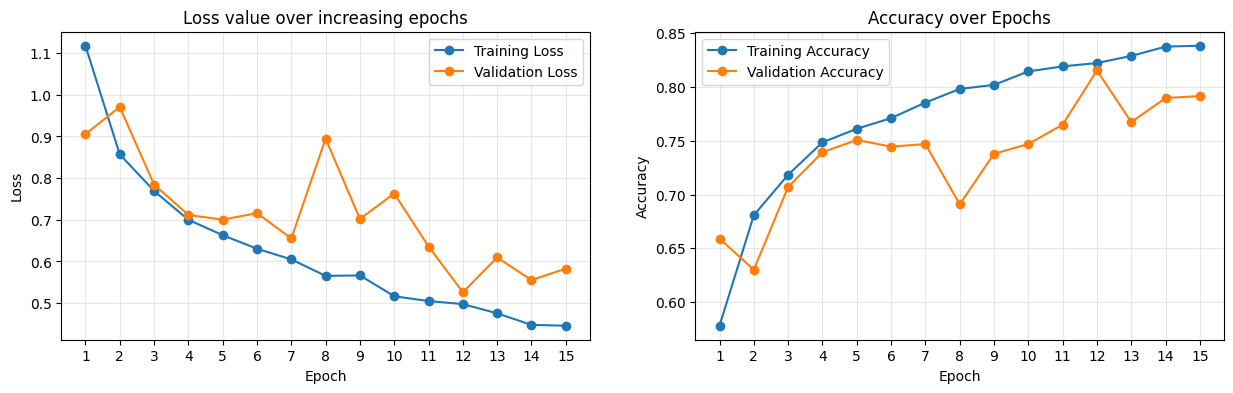

In [10]:
## 10. Visualizations (Loss and Accuracy Curves)
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [11]:
## 11. Evaluate Model on Test Set, Confusion Matrix & Save
from sklearn.metrics import confusion_matrix

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

all_predictions, all_labels = [], []
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        prediction = model(x)
        predicted_labels = prediction.argmax(-1)
        all_predictions.extend(predicted_labels.cpu().tolist())
        all_labels.extend(y.tolist())

cm = confusion_matrix(all_labels, all_predictions)
print("\nConfusion Matrix:")
print(cm)

# Save Model
torch.save(model.state_dict(), "CNN_Intel_Image_Classification.pth")
print("\nModel saved successfully!")

Test Loss: 0.5188
Test Accuracy: 82.27%

Confusion Matrix:
[[362   2   6  12   6  49]
 [ 12 408   2   6   2  44]
 [  6   0 456  64  12  15]
 [  5   0  59 445  12   4]
 [ 31   1  54  62 357   5]
 [ 48   2   3   4   4 440]]

Model saved successfully!
